# Klasifikasi Audio Berisik vs Non-Berisik

## 1. Bussiness Understanding

### 1.1 Latar Belakang

Lingkungan laboratorium di Universitas Trunojoyo Madura (UTM) memiliki dinamika akustik yang beragam. Dalam kondisi operasional normal, suasana lab diisi oleh aktivitas mahasiswa seperti berdiskusi, berkolaborasi, bermain, serta suara operasional perangkat keras seperti pendingin ruangan (AC).

Kondisi suara di dalam laboratorium dapat dikategorikan secara garis besar menjadi dua kondisi utama:

1. Kondisi Non-Berisik (Tenang/Hening): Suasana ketika mahasiswa fokus bekerja secara mandiri, didominasi oleh latar belakang yang konstan dan stabil (steady-state background noise) seperti dengungan AC dan diskusi ringan mahasiswa.

2. Kondisi Berisik (Rame/Gaduh): Suasana ketika terjadi interaksi sosial yang intensif, diskusi kelompok yang ramai, gelak tawa, atau aktivitas bergerak yang menghasilkan energi akustik impulsif dan fluktuatif.

Kemampuan sistem cerdas untuk mengenali dan mengklasifikasikan kondisi akustik ini secara otomatis sangat berguna untuk pemantauan tingkat kebisingan ruangan,  pengelolaan fasilitas kampus yang adaptif, maupun sebagai sistem pendukung manajemen kualitas kenyamanan belajar.

### 1.2 Tujuan

Tujuan dari proyek ini adalah membangun sistem klasifikasi biner berbasis **Machine Learning** menggunakan algoritma **Support Vector Machine (SVM)** untuk mendeteksi apakah suatu sampel rekaman audio laboratorium di lingkungan UTM termasuk dalam kategori berisik atau non-berisik berdasarkan ekstraksi fitur akustik (``RMS``, ``Spectral Centroid``, ``ZCR``, dan ``MFCC``).




## 2. Data Understanding

Dataset terdiri atas rekaman suara riil berformat ``.mp3`` dengan laju percontohan (sampling rate) $f_s = 22050\text{ Hz}$, dikelompokkan ke dalam dua kelas biner:

- ``berisik``: Rekaman lingkungan berisik

- ``non-berisik``: Rekaman lingkungan hening/tenang

### 2.1 Ringkasan Sample Data 

Total Sample Audio ``200`` sample audio yang terdiri dari:

- ``Kelas Berisik 100 sample``

- ``Kelas Non-Berisik 100 sample``

### 2.2 Ekstraksi Fitur Audio

#### 2.2.1 RMS (Root Mean Square)

##### a. Definisi RMS
Root Mean Square (RMS) adalah ukuran daya rata-rata atau energi efektif dari sinyal audio dalam suatu jendela waktu (frame). Dalam persepsi manusia, RMS berkorelasi langsung dengan tingkat kenyaringan (loudness) suara:

- Audio ``berisik`` Ketika banyak mahasiswa bersuara bersamaan, tertawa, atau berseru, amplitudo gelombang naik secara signifikan. Nilai rata-rata RMS akan jauh lebih tinggi dibanding kondisi tenang.

- Audio ``non-berisik`` Hanya terdengar dengungan AC, kipas PC lab, atau ketikan tuts keyboard sesekali, dan mahasiswa yang berdiskusi tidak ramai sehingga RMS mendekati nol (amplitudo rendah).

##### b. Rumus Matematis :

Untuk sebuah frame sinyal diskret $x[n]$ dengan panjang $N$ sampel, nilai RMS dihitung sebagai:

$$RMS = \sqrt{\frac{1}{N} \sum_{n=0}^{N-1} \vert{}x[n]\vert{}^2}$$

Di mana:

$N$ = panjang frame (misal: 2048 sampel)

$x[n]$ = amplitudo sinyal audio pada sampel ke-$n$

##### c. Contoh Perhitungan

Misalkan kita memiliki satu frame kecil berisi 5 sampel sinyal:

$$x = [0.1, -0.2, 0.4, -0.3, 0.1]$$

1. Kuadratkan setiap sampel ($x[n]^2$):

$$x = [0.1^2, -0.2^2, 0.4^2, -0.3^2, 0.1^2]$$

$$x = [0.01, 0.04, 0.16, 0.09, 0.01]$$

2. Hitung jumlah kuadrat ($\sum \vert{}x[n]\vert{}^2$):

$$\sum = 0.01 + 0.04 + 0.16 + 0.09 + 0.01 = 0.31$$

3. Bagi dengan jumlah sampel ($N = 5$):

$$\text{Mean} = \frac{0.31}{5} = 0.062$$

4. Akar Kuadrat Hasilnya:

$$RMS = \sqrt{0.062} \approx 0.24899$$


#### 2.2.2 Spectral Centroid

##### a. Definisi Spectral Centroid
Spectral Centroid adalah ukuran yang menunjukkan letak pusat massa (titik berat frekuensi) dari suatu spektrum suara. Dalam persepsi manusia, Spectral Centroid diasosiasikan dengan "kecerahan" (brightness) suara.

- Audio ``berisik`` Suara tawa melengking, gesekan kaki meja/kursi lab ke lantai keramik, atau teriakan menghasilkan komponen frekuensi menengah-tinggi yang dominan. Ini menarik titik berat spektrum ke frekuensi yang lebih tinggi (Hz besar).

- Audio ``non-berisik`` Lab kosong/hening biasanya didominasi oleh suara berfrekuensi rendah (low-frequency rumble) dari perangkat komputer atau ventilasi udara, sehingga centroid-nya lebih rendah.

Cara Kerja Pada Code:

``centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]``

Penjelasan:

Sinyal dibagi per frame ``(frame_length = 2048, hop_length = 512)``. Sinyal tiap frame diubah dari domain waktu ke domain frekuensi menggunakan STFT (Short-Time Fourier Transform). Dihitung nilai spectral centroid (dalam satuan Hertz / Hz) untuk tiap frame. Di tahap pembuatan dataset, dirata-ratakan dengan np.mean(centroid) untuk mewakili 1 file audio.

##### b. Rumus Matematis :

Untuk sebuah frame ke-$t$:

$$\text{Centroid}_t = \frac{\sum_{k=0}^{N-1} f(k) \cdot \vert{}S_t(k)\vert{}}{\sum_{k=0}^{N-1} \vert{}S_t(k)\vert{}}$$

Di mana:

$f(k)$: Frekuensi tengah pada bin/pita frekuensi ke-$k$ (dalam Hz)

$\vert{}S_t(k)\vert{}$: Magnitudo (besaran energi) spektrum pada bin ke-$k$

Prinsip rumus ini sama persis dengan rata-rata tertimbang (weighted average): frekuensi dikalikan magnitudonya, lalu dibagi total magnitudo.

##### c. Contoh Perhitungan

Misalkan pada satu frame hasil Fourier Transform, terdapat 3 pita frekuensi ($k=0, 1, 2$):

- Bin $(k)$ = $1, 2, 3$

- Frekuensi $f(k) (Hz)$ = $500Hz, 1000Hz, 2000Hz$

- Magnitudo $\vert{}S_t(k)\vert{}$ = $2, 5, 1$

1. Hitung pembilang (Jumlah Frekuensi $\times$ Magnitudo):

$$\text{Pembilang} = (500 \times 2) + (1000 \times 5) + (2000 \times 1) = 1000 + 5000 + 2000 = 8000$$

2. Hitung penyebut (Total Magnitudo):

$$\text{Penyebut} = 2 + 5 + 1 = 8$$

3. Hitung Centroid:

$$\text{Centroid} = \frac{8000}{8} = 1000\text{ Hz}$$

Artinya, pusat energi frekuensi pada frame ini berada di sekitar 1000 Hz.

#### 2.2.3 ZCR (Zero Crossing Rate)

##### a. Definisi ZCR (Zero Crossing Rate)
Zero Crossing Rate (ZCR) adalah laju atau tingkat seberapa sering sinyal audio gelombang domain waktu berpindah tanda dari positif ke negatif atau sebaliknya (memotong garis amplitudo nol) dalam rentang waktu tertentu.

- Audio ``berisik`` Obrolan banyak orang yang bertumpuk (babble noise), suara tawa terbahak-bahak, dan gesekan benda menghasilkan gelombang acak yang sering berganti tanda positif-negatif, sehingga ZCR cenderung lebih tinggi dan bervariasi.

- Audio ``non-berisik`` Gelombang suara latar lab cenderung stabil dan monoton, menghasilkan ZCR yang lebih teratur dan rendah.

Cara Kerja Pada Code:

``zcr = librosa.feature.zero_crossing_rate(y=y)[0]``

Penjelasan:

Sinyal dibagi per frame ``(frame_length = 2048, hop_length = 512)``. Dihitung rasio berapa kali sinyal berganti tanda dibagi panjang frame. Pada pembuatan dataset, dirata-ratakan dengan ``np.mean(zcr)``.

##### b. Rumus Matematis

Untuk frame ke-$t$ dengan panjang sample $K$:

$$\text{ZCR}_t = \frac{1}{2(K - 1)} \sum_{n=1}^{K-1} \left\vert{} \text{sgn}(y_t[n]) - \text{sgn}(y_t[n-1]) \right\vert{}$$

Di mana fungsi tanda $\text{sgn}(x)$ didefinisikan:

$$\text{sgn}(x) = \begin{cases} 1, & \text{jika } x \ge 0 \\ -1, & \text{jika } x < 0 \end{cases}$$

- Jika dua sampel berturutan tandanya berbeda (misal $+1$ dan $-1$), maka $\vert{}1 - (-1)\vert{} = 2$

- Faktor $\frac{1}{2}$ menormalkannya menjadi hitungan $1$ perpotongan

- Pembagian dengan $(K-1)$ menghasilkan nilai rasio rentang $0$ sampai $1$


##### c. Contoh Perhitungan Manual

Misalkan sebuah frame pendek memiliki $K = 5$ sampel amplitudo:

$$y = [0.2, -0.4, 0.1, 0.3, -0.2]$$

1. Cek Perubahan Tanda antar sample berturutan

- Sampel 1 ($0.2$) ke Sampel 2 ($-0.4$): Berubah tanda (Positif $\rightarrow$ Negatif) $\rightarrow$ Hitung = 1

- Sampel 2 ($-0.4$) ke Sampel 3 ($0.1$): Berubah tanda (Negatif $\rightarrow$ Positif) $\rightarrow$ Hitung = 1

- Sampel 3 ($0.1$) ke Sampel 4 ($0.3$): Tidak berubah (Positif $\rightarrow$ Positif) $\rightarrow$ Hitung = 0

- Sampel 4 ($0.3$) ke Sampel 5 ($-0.2$): Berubah tanda (Positif $\rightarrow$ Negatif) $\rightarrow$ Hitung = 1

2. Total Perpotongan Nol

$$\text{Total crossing} = 1 + 1 + 0 + 1 = 3$$

3. Hitung ZCR

$$\text{ZCR} = \frac{3}{K - 1} = \frac{3}{5 - 1} = \frac{3}{4} = 0.75$$

Nilai ZCR frame tersebut adalah 0.75 (artinya 75% dari transisi sampel memotong garis nol).


#### 2.2.4 MFCC (Mel-Frequency Cepstral Coefficients)

##### a. Definisi MFCC
MFCC adalah fitur representasi spektrum suara yang meniru cara pendengaran manusia (koklea telinga) mempersepsikan frekuensi. Telinga manusia sangat sensitif membedakan nada pada frekuensi rendah (di bawah $1000\text{ Hz}$), tetapi kurang sensitif membedakan perubahan nada pada frekuensi tinggi. Pada data ini, diambil 13 koefisien ``(n_mfcc=13)`` yang merepresentasikan amplop spektrum (spectral envelope), bentuk timbre suara, dan resonansi akustik. MFCC sangat efektif membedakan "suara manusia yang sedang bersahut-sahutan/bercanda" dari "suara dengung mesin/perangkat lab", bahkan jika desibel (RMS) AC lab kebetulan cukup keras.

Cara Kerja Pada Code:

``mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)``

Penjelasan:

Output mfcc berbentuk matriks $(13 \times M)$, di mana baris 1 s.d. 13 adalah koefisien ``mfcc_1`` sampai ``mfcc_13``, dan kolom $M$ adalah jumlah frame.

##### b. Rumus Matematis

Proses pembentukan MFCC terdiri dari 5 tahapan berurutan:

1. Fourier Transform (STFT)

Sinyal per-frame diubah ke spektrum daya (Power Spectrum):

$$P(k) = \vert{}S(k)\vert{}^2$$

2. Konversi ke skala Mel

Frekuensi $f$ (dalam Hz) diubah ke skala Mel $m$:

$$m = 2595 \cdot \log_{10} \left(1 + \frac{f}{700}\right)$$

3. Mel-Filterbank:

Spektrum daya dilewatkan pada susunan filter segitiga (biasanya 40 atau 128 filter Mel). Energi pada setiap filter ke-$m$ dijumlahkan:

$$E(m) = \sum_{k} P(k) \cdot H_m(k)$$

4. Logarithmic Compression:

Mengambil logaritma dari energi filterbank (karena telinga manusia mendengar kenyaringan suara secara logaritmik/desibel):

$$\widetilde{E}(m) = \ln(E(m))$$

5. Discrete Cosine Transform (DCT):

DCT diterapkan pada energi logaritma tersebut untuk mereduksi korelasi antar filter dan memisahkan amplop spektrum:

$$c_n = \sum_{m=1}^{M_{\text{filters}}} \widetilde{E}(m) \cdot \cos\left[ \frac{\pi n}{M_{\text{filters}}} \left(m - \frac{1}{2}\right) \right]$$

Di mana $n = 1, 2, \dots, 13$ adalah koefisien MFCC ke-$n$.


##### c. Contoh Perhitungan Manual

Misalkan setelah melalui Mel-Filterbank dan logaritma, didapatkan nilai log-energi pada 3 filter Mel ($M_{\text{filters}} = 3$):

$$\widetilde{E} = [\widetilde{E}_1, \widetilde{E}_2, \widetilde{E}_3] = [3.0, 2.0, 1.0]$$

Kita hitung koefisien MFCC ke-1 ($n = 1$):

Rumus per suku:

$$c_1 = \sum_{m=1}^{3} \widetilde{E}_m \cdot \cos\left( \frac{\pi \cdot 1}{3} \left(m - 0.5\right) \right)$$

- Untuk $m = 1$

$$\text{sudut} = \frac{\pi}{3}(1 - 0.5) = \frac{\pi}{6} = 30^\circ \implies \cos(30^\circ) \approx 0.866$$

$$\text{Suku 1} = 3.0 \times 0.866 = 2.598$$

- Untuk $m = 2$

$$\text{sudut} = \frac{\pi}{3}(2 - 0.5) = \frac{\pi}{2} = 90^\circ \implies \cos(90^\circ) = 0$$

$$\text{Suku 2} = 2.0 \times 0 = 0$$

- Untuk $m = 3$

$$\text{sudut} = \frac{\pi}{3}(3 - 0.5) = \frac{5\pi}{6} = 150^\circ \implies \cos(150^\circ) \approx -0.866$$

$$\text{Suku 3} = 1.0 \times (-0.866) = -0.866$$

- Hasil $c_1$ (MFCC 1):

$$c_1 = 2.598 + 0 + (-0.866) = 1.732$$

Proses yang sama diulang untuk $n = 2, 3, \dots, 13$ untuk menghasilkan 13 koefisien MFCC.

### 2.3 Visualisasi Time-Series Fitur

Visualisasi time-series membedah perilaku audio secara dinamis per jendela waktu (time-frame):

1. ``Waveform`` (Amplitudo vs Waktu): Memetakan deviasi tekanan udara. Audio berisik memiliki kerapatan amplitudo tinggi sepanjang rekaman.

2. ``RMS`` vs ``Waktu``: Menampilkan fluktuasi energi sesaat; puncak-puncak tajam menandai suara impulsif atau desau konstan.

3. ``Spectral Centroid`` vs ``Waktu``: Menunjukkan variasi pusat frekuensi dari waktu ke waktu.

4. ``Zero Crossing Rate`` vs ``Waktu``: Menilai tingkat keacakan sinyal audio sepanjang durasi rekaman.

#### 2.3.1 Visualisasi Menggunakan Sample ``berisik``

c:\Users\LENOVO\miniforge3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


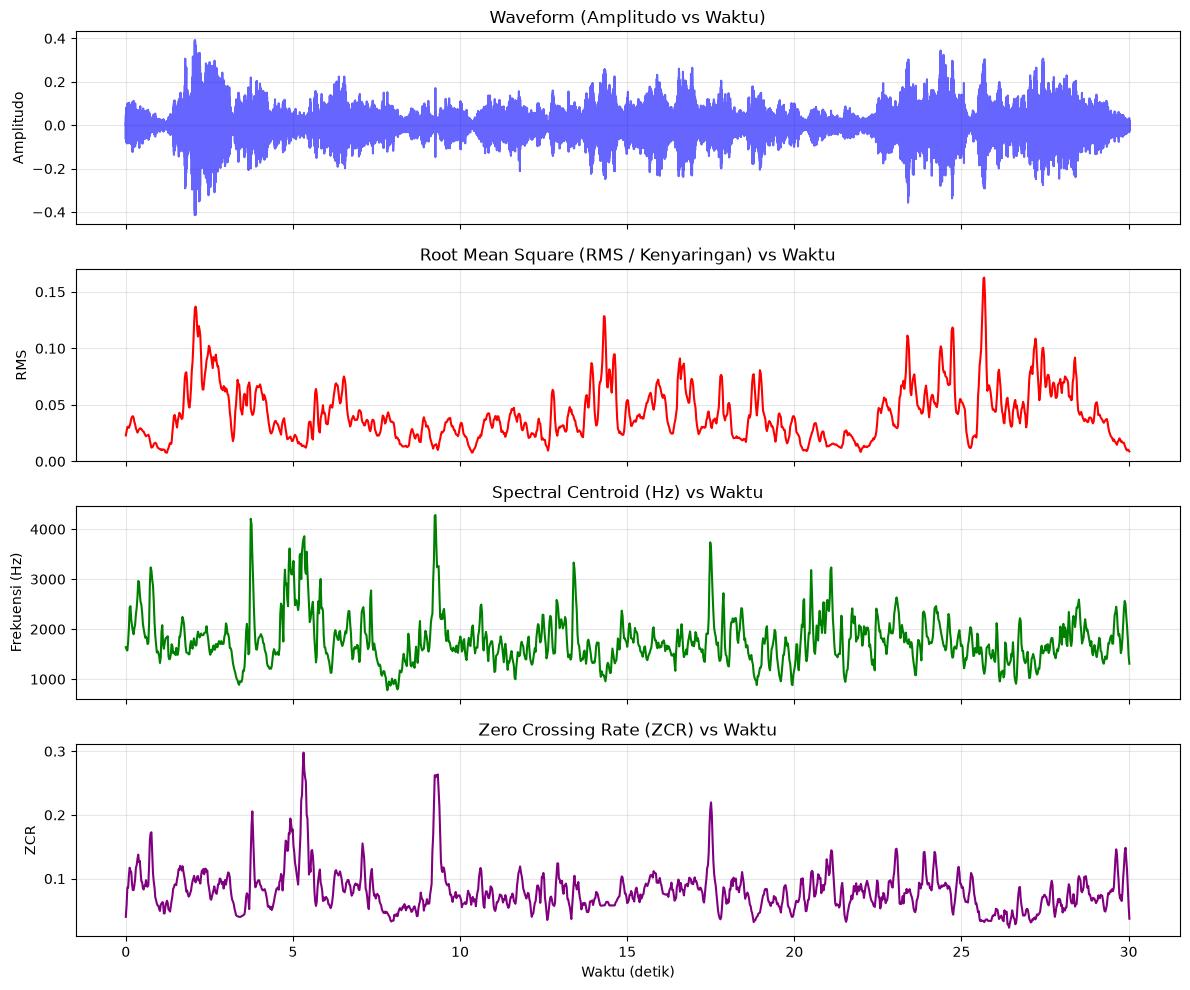

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# 1. Muat file audio
file_path = "berisik/24-003 berisik (1).mp3"  # Ganti dengan file audio Anda
y, sr = librosa.load(file_path, sr=22050)

# 2. Ekstraksi fitur per-frame (jangan dirata-ratakan)
rms = librosa.feature.rms(y=y)[0]
centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
zcr = librosa.feature.zero_crossing_rate(y=y)[0]

# 3. Hitung sumbu waktu (detik) untuk tiap frame
frames = range(len(rms))
t_frames = librosa.frames_to_time(frames, sr=sr)
t_wave = np.linspace(0, len(y) / sr, len(y))

# 4. Plot Visualisasi Time Series
fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

# Subplot 1: Waveform (Bentuk Gelombang Amplitudo)
axs[0].plot(t_wave, y, color='blue', alpha=0.6)
axs[0].set_title("Waveform (Amplitudo vs Waktu)")
axs[0].set_ylabel("Amplitudo")
axs[0].grid(True, alpha=0.3)

# Subplot 2: RMS (Energi / Kenyaringan Suara)
axs[1].plot(t_frames, rms, color='red', linewidth=1.5)
axs[1].set_title("Root Mean Square (RMS / Kenyaringan) vs Waktu")
axs[1].set_ylabel("RMS")
axs[1].grid(True, alpha=0.3)

# Subplot 3: Spectral Centroid (Kecerahan Frekuensi)
axs[2].plot(t_frames, centroid, color='green', linewidth=1.5)
axs[2].set_title("Spectral Centroid (Hz) vs Waktu")
axs[2].set_ylabel("Frekuensi (Hz)")
axs[2].grid(True, alpha=0.3)

# Subplot 4: Zero Crossing Rate
axs[3].plot(t_frames, zcr, color='purple', linewidth=1.5)
axs[3].set_title("Zero Crossing Rate (ZCR) vs Waktu")
axs[3].set_xlabel("Waktu (detik)")
axs[3].set_ylabel("ZCR")
axs[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### 2.3.2 Visualisasi Menggunakan Sample ``non-berisik``

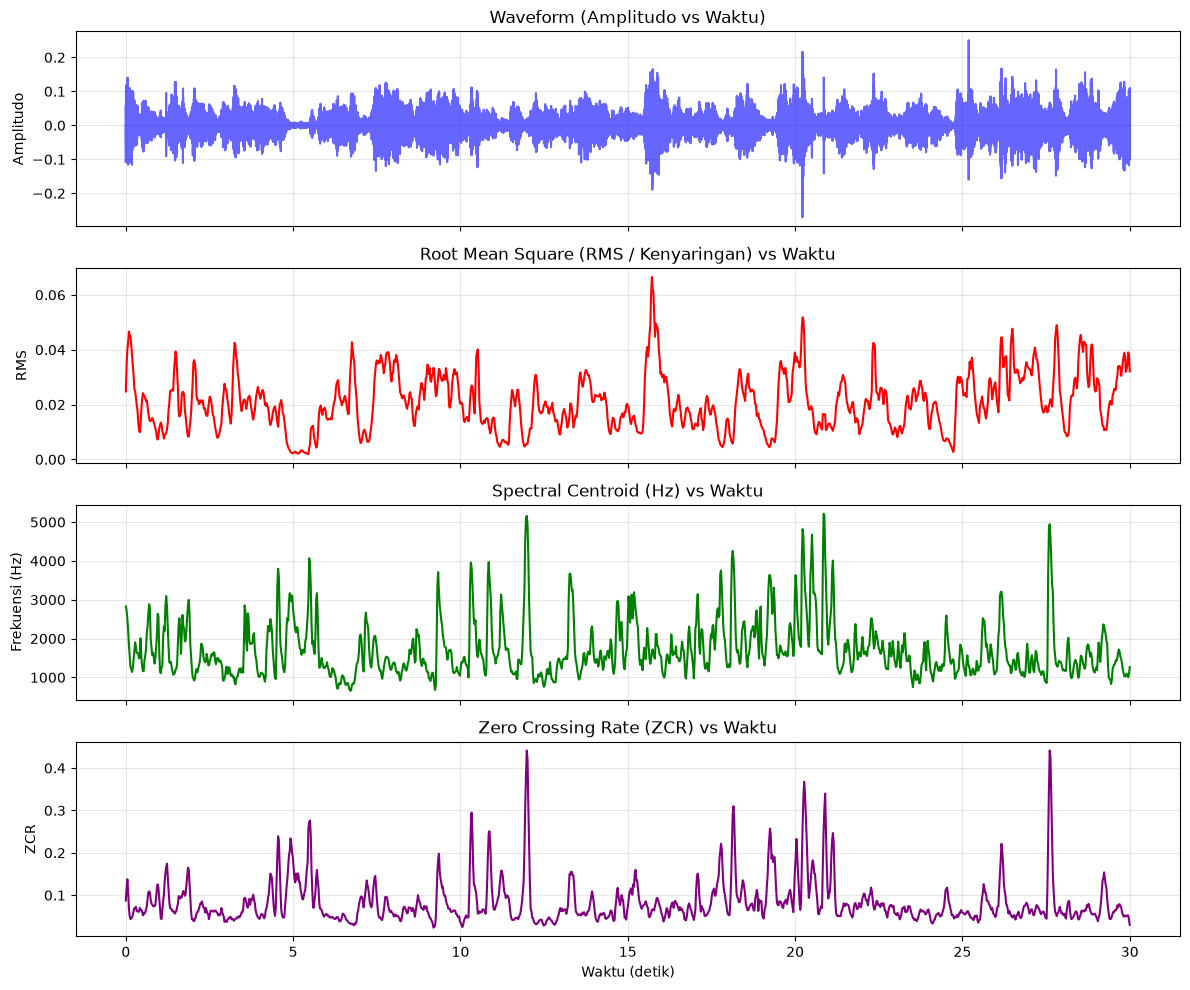

In [35]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# 1. Muat file audio
file_path = "non-berisik/24-003 sunyi 2.mp3"  # Ganti dengan file audio Anda
y, sr = librosa.load(file_path, sr=22050)

# 2. Ekstraksi fitur per-frame (jangan dirata-ratakan)
rms = librosa.feature.rms(y=y)[0]
centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
zcr = librosa.feature.zero_crossing_rate(y=y)[0]

# 3. Hitung sumbu waktu (detik) untuk tiap frame
frames = range(len(rms))
t_frames = librosa.frames_to_time(frames, sr=sr)
t_wave = np.linspace(0, len(y) / sr, len(y))

# 4. Plot Visualisasi Time Series
fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

# Subplot 1: Waveform (Bentuk Gelombang Amplitudo)
axs[0].plot(t_wave, y, color='blue', alpha=0.6)
axs[0].set_title("Waveform (Amplitudo vs Waktu)")
axs[0].set_ylabel("Amplitudo")
axs[0].grid(True, alpha=0.3)

# Subplot 2: RMS (Energi / Kenyaringan Suara)
axs[1].plot(t_frames, rms, color='red', linewidth=1.5)
axs[1].set_title("Root Mean Square (RMS / Kenyaringan) vs Waktu")
axs[1].set_ylabel("RMS")
axs[1].grid(True, alpha=0.3)

# Subplot 3: Spectral Centroid (Kecerahan Frekuensi)
axs[2].plot(t_frames, centroid, color='green', linewidth=1.5)
axs[2].set_title("Spectral Centroid (Hz) vs Waktu")
axs[2].set_ylabel("Frekuensi (Hz)")
axs[2].grid(True, alpha=0.3)

# Subplot 4: Zero Crossing Rate
axs[3].plot(t_frames, zcr, color='purple', linewidth=1.5)
axs[3].set_title("Zero Crossing Rate (ZCR) vs Waktu")
axs[3].set_xlabel("Waktu (detik)")
axs[3].set_ylabel("ZCR")
axs[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. PreProcessing & Ekstraksi Fitur

Memuat file audio ``.mp3`` kondisi lab UTM menggunakan pustaka ``librosa`` pada sampling rate terstandarisasi $22050\text{ Hz}$. Mengekstraksi parameter numerik yaitu ``RMS``, ``Spectral Centroid``, ``ZCR``, dan ``13 koefisien MFCC`` (total 16 fitur). Melakukan averaging (rata-rata per file audio) guna merepresentasikan karakteristik satu file ke dalam satu baris data tabular.

### 3.1 Ekstraksi Fitur Audio Berlabel ``berisik``

In [17]:
import os
import librosa
import numpy as np
import pandas as pd

def extract_features_from_mp3_folder(folder_path, label="berisik"):
    dataset = []

    for file in os.listdir(folder_path):
        if file.lower().endswith('.mp3'):
            full_path = os.path.join(folder_path, file)
            
            try:
                # Muat file MP3
                y, sr = librosa.load(full_path, sr=22050)

                # Ekstraksi 4 fitur utama
                rms = librosa.feature.rms(y=y)
                centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
                zcr = librosa.feature.zero_crossing_rate(y=y)
                mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

                row_data = {
                    'filename': file,
                    'rms': np.mean(rms),
                    'centroid': np.mean(centroid),
                    'zcr': np.mean(zcr),
                    }

                # Masukkan 13 koefisien MFCC langsung
                mfcc_mean = np.mean(mfcc, axis=1)
                for i, val in enumerate(mfcc_mean, start=1):
                    row_data[f'mfcc_{i}'] = val

                # Masukkan label di akhir dictionary
                row_data['label'] = label

                dataset.append(row_data)
                print(f"Selesai: {file}")

            except Exception as e:
                print(f"Error memproses {file}: {e}")

    return pd.DataFrame(dataset)

# Jalankan untuk folder yang diinginkan
folder_mp3 = "berisik"
label_target = "berisik"  # Sesuaikan label kelasnya

df = extract_features_from_mp3_folder(folder_mp3, label=label_target)
df.to_csv("fitur_mp3_berisik.csv", index=False)

print("\nData berhasil disimpan ke 'fitur_mp3_berisik.csv'")
print(df.head())

Selesai: 24-003 berisik (1).mp3
Selesai: 24-003 berisik (2).mp3
Selesai: 24-003 berisik (3).mp3
Selesai: 24-006 berisik 1.mp3
Selesai: 24-006 berisik 2.mp3
Selesai: 24-006 berisik 3.mp3
Selesai: 24-007 berisikk 1.mp3
Selesai: 24-007 berisikkk 2.mp3
Selesai: 24-007 berisikkk 3.mp3
Selesai: 24-026 berisik 1.mp3
Selesai: 24-026 berisik 2.mp3
Selesai: 24-026 berisik 3.mp3
Selesai: 24-027_berisik1.mp3
Selesai: 24-027_berisik2.mp3
Selesai: 24-027_berisik3.mp3
Selesai: 24-031 berisik 1.mp3
Selesai: 24-031 berisik 2.mp3
Selesai: 24-031 berisik 3.mp3
Selesai: 24-034 berisik 1.mp3
Selesai: 24-034 berisik 2.mp3
Selesai: 24-034 berisik 3.mp3
Selesai: 24-053 berisik 1.mp3
Selesai: 24-053 berisik 3.mp3
Selesai: 24-068 Berisik 1.mp3
Selesai: 24-068 Berisik 2.mp3
Selesai: 24-068 Berisik 3.mp3
Selesai: 24-071 berisik 1.mp3
Selesai: 24-071 berisik 2.mp3
Selesai: 24-071 berisik 3.mp3
Selesai: 24-078_Berisik 1.mp3
Selesai: 24-078_Berisik 2.mp3
Selesai: 24-078_Berisik 3.mp3
Selesai: 24-079 berisik 1.mp3
Se

### 3.2 Ekstraksi Fitur Audio Berlabel ``non-berisik``

In [16]:
import os
import librosa
import numpy as np
import pandas as pd

def extract_features_from_mp3_folder(folder_path, label="non-berisik"):
    dataset = []

    for file in os.listdir(folder_path):
        if file.lower().endswith('.mp3'):
            full_path = os.path.join(folder_path, file)
            
            try:
                # Muat file MP3
                y, sr = librosa.load(full_path, sr=22050)

                # Ekstraksi 4 fitur utama
                rms = librosa.feature.rms(y=y)
                centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
                zcr = librosa.feature.zero_crossing_rate(y=y)
                mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

                row_data = {
                    'filename': file,
                    'rms': np.mean(rms),
                    'centroid': np.mean(centroid),
                    'zcr': np.mean(zcr),
                    }

                # Masukkan 13 koefisien MFCC langsung
                mfcc_mean = np.mean(mfcc, axis=1)
                for i, val in enumerate(mfcc_mean, start=1):
                    row_data[f'mfcc_{i}'] = val

                # Masukkan label di akhir dictionary
                row_data['label'] = label

                dataset.append(row_data)
                print(f"Selesai: {file}")

            except Exception as e:
                print(f"Error memproses {file}: {e}")

    return pd.DataFrame(dataset)

# Jalankan untuk folder yang diinginkan
folder_mp3 = "non-berisik"
label_target = "non-berisik"  # Sesuaikan label kelasnya

df = extract_features_from_mp3_folder(folder_mp3, label=label_target)
df.to_csv("fitur_mp3_non_berisik.csv", index=False)

print("\nData berhasil disimpan ke 'fitur_mp3_non_berisik.csv'")
print(df.head())

Selesai: 24-003 sunyi 2.mp3
Selesai: 24-003 sunyi 3.mp3
Selesai: 24-006 non-berisik 1.mp3
Selesai: 24-006 non-berisik 2.mp3
Selesai: 24-006 non-berisik 3.mp3
Selesai: 24-007 non-berisik 1.mp3
Selesai: 24-007 non-berisik 2.mp3
Selesai: 24-007 non-berisik 3.mp3
Selesai: 24-026 non-berisik 1.mp3
Selesai: 24-026 non-berisik 2.mp3
Selesai: 24-026 non-berisik 3.mp3
Selesai: 24-027_non-berisik1.mp3
Selesai: 24-027_non-berisik2.mp3
Selesai: 24-027_non-berisik3.mp3
Selesai: 24-031 non-berisik 1.mp3
Selesai: 24-031 non-berisik 2.mp3
Selesai: 24-031 non-berisik 3.mp3
Selesai: 24-034 non-berisik 1.mp3
Selesai: 24-034 non-berisik 2.mp3
Selesai: 24-034 non-berisik 3.mp3
Selesai: 24-053 non-berisik 1.mp3
Selesai: 24-053 non-berisik 2.mp3
Selesai: 24-053 non-berisik 3.mp3
Selesai: 24-068 non-berisik 1.mp3
Selesai: 24-068 non-berisik 2.mp3
Selesai: 24-068 non-berisik 3.mp3
Selesai: 24-071 non berisik 1.mp3
Selesai: 24-071 non berisik 2.mp3
Selesai: 24-071 non berisik 3.mp3
Selesai: 24-078_NonBerisik 1.

### 3.3 Penggabungan File berlabel ``berisik`` dan ``non-berisik``

In [18]:
import pandas as pd

# 1. Baca kedua file CSV hasil ekstraksi
df_berisik = pd.read_csv("fitur_mp3_berisik.csv")
df_non_berisik = pd.read_csv("fitur_mp3_non_berisik.csv")

# 2. Pastikan kolom label sudah terisi dengan benar (opsional jika sudah ada)
df_berisik['label'] = 'berisik'
df_non_berisik['label'] = 'non-berisik'

# 3. Gabungkan kedua dataframe menjadi satu
df_final = pd.concat([df_berisik, df_non_berisik], ignore_index=True)

# 4. Acak urutan baris data agar label tidak berkumpul di satu sisi (disarankan)
df_final = df_final.sample(frac=1, random_state=42).reset_index(drop=True)

# 5. Simpan ke satu file CSV utama
df_final.to_csv("dataset_audio_final.csv", index=False)

print("Penggabungan selesai!")
print(f"Total baris data: {len(df_final)}")
print("\nDistribusi kelas:")
print(df_final['label'].value_counts())
print("\nContoh 5 baris pertama:")
print(df_final.head())

Penggabungan selesai!
Total baris data: 200

Distribusi kelas:
label
berisik        100
non-berisik    100
Name: count, dtype: int64

Contoh 5 baris pertama:
                   filename       rms     centroid       zcr      mfcc_1  \
0      24-202_berisik 1.MP3  0.039446  2332.918964  0.112436 -223.110340   
1      24-031 berisik 1.mp3  0.244896  1739.843446  0.070094  -62.173183   
2      24-078_Berisik 2.mp3  0.089509  1789.151732  0.102397 -202.780530   
3  24-119 non-berisik 3.mp3  0.029280  1930.658290  0.076982 -250.625000   
4  24-071 non berisik 3.mp3  0.007862  2286.734913  0.076706 -366.981500   

       mfcc_2     mfcc_3     mfcc_4     mfcc_5     mfcc_6     mfcc_7  \
0   95.422646 -18.105993  14.040424 -11.892736 -11.998929  -7.546864   
1  121.653680  -0.846771  19.761806   6.068880   0.267776  -3.729231   
2  114.147804 -44.899210  19.832167 -26.086739  -2.822680 -11.758299   
3  115.553170  -4.067587  24.176480  -1.427832  -5.453652  -9.229185   
4   94.904400  20.217993 

### 3.4 Seleksi Fitur

Dalam pengembangan sistem klasifikasi audio laboratorium Universitas Trunojoyo Madura ini, tidak dilakukan seleksi fitur menggunakan metode apapun. Berdasarkan eksperimen dan pengujian empiris yang telah dilakukan, penerapan seleksi fitur justru berdampak negatif terhadap performa model, di mana akurasi klasifikasi SVM mengalami penurunan yang signifikan. 

Alasan utama mengapa seluruh 16 fitur dipertahankan secara utuh (full-feature set) karena Ke-16 fitur yang diekstraksi—yang mencakup RMS (energi/kenyaringan), Spectral Centroid (titik berat frekuensi), ZCR (tingkat perpotongan nol), serta 13 koefisien MFCC—masing-masing membawa informasi karakteristik spektral dan temporal yang spesifik dari suara lingkungan laboratorium UTM (seperti dengungan perangkat lab vs suara aktivitas interaksi mahasiswa). Dengan total hanya 16 fitur, dimensi data tergolong sangat kecil dan ringan untuk diproses oleh algoritma SVM. Oleh karena itu, penggunaan seluruh fitur secara langsung (raw features)

### 4. Pemodelan Menggunakan Support Vector Machine (SVM) dan Evaluasi Model

Model klasifikasi yang digunakan adalah **Support Vector Machine (SVM)** dengan kernel **Radial Basis Function (RBF)**. Pembagian Data (Data Splitting) **80% data latih (training)** dan **20% data uji (testing)**. Menerapkan ``StandardScaler`` agar seluruh rentang fitur memiliki mean nol dan variansi satu, mencegah dominasi skala fitur tertentu terhadap performa SVM. Menggunakan ``Stratified K-Fold`` ($k = 5$) untuk memastikan distribusi kelas seimbang pada setiap iterasi.

Setelah dilakukan pemodelan, maka akan dilakukan evaluasi model menggunakan metrik standar klasifikasi (confusion matriks) yang terdiri dari:

- Akurasi (Accuracy): Persentase total prediksi benar terhadap keseluruhan data uji.

- Presisi (Precision): Ketepatan model dalam memprediksi kelas positif.

- Recall (Sensitivity): Kemampuan model menemukan kembali suatu kelas tertentu.

- F1-Score: Perimbangan harmonis antara Presisi dan Recall.

- Confusion Matrix: Matriks visualisasi performa prediksi benar vs salah untuk tiap kelas.

PROSES TRAINING DAN EVALUASI MODEL SVM (16 FITUR)
Jumlah Data Training (Latih) : 160 sampel
Jumlah Data Testing (Uji)    : 40 sampel
-----------------------------------------------------------------


c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.

Skor Cross-Validation (5-Fold) : 85.00%
Train Accuracy                 : 94.38%
Test Accuracy                  : 80.00%
-----------------------------------------------------------------

Classification Report (pada Data Uji):
              precision    recall  f1-score   support

     berisik       0.88      0.70      0.78        20
 non-berisik       0.75      0.90      0.82        20

    accuracy                           0.80        40
   macro avg       0.81      0.80      0.80        40
weighted avg       0.81      0.80      0.80        40



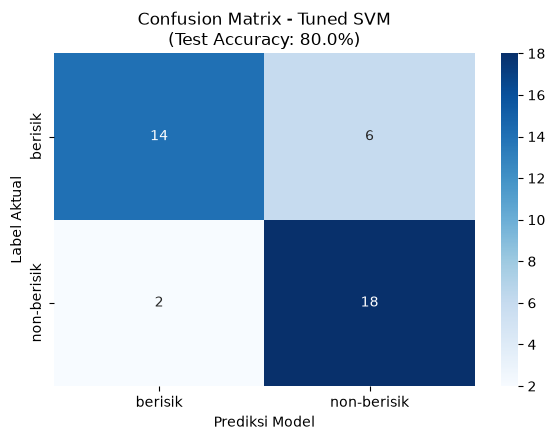

Model SVM dan artefak pendukung berhasil disimpan!


In [34]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("=" * 65)
print("PROSES TRAINING DAN EVALUASI MODEL SVM (16 FITUR)")
print("=" * 65)

# 1. Muat Dataset Final (16 Fitur Asli)
df = pd.read_csv("dataset_audio_final.csv")
X = df.drop(columns=['filename', 'label'])
y = df['label']

# 2. Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Cetak Jumlah Data Training dan Testing
print(f"Jumlah Data Training (Latih) : {X_train.shape[0]} sampel")
print(f"Jumlah Data Testing (Uji)    : {X_test.shape[0]} sampel")
print("-" * 65)

# 4. Standarisasi Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Inisialisasi Model Tuned SVM (Parameter optimal: C=2.0, gamma=0.1)
svm_model = SVC(
    C=2.0,
    gamma=0.1,
    kernel='rbf',
    probability=True,
    class_weight='balanced',
    random_state=42
)

# Cross-Validation 5-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(svm_model, X_train_scaled, y_train, cv=cv, scoring='accuracy')

# Training Model pada Data Latih
svm_model.fit(X_train_scaled, y_train)

# Prediksi untuk Evaluasi
y_train_pred = svm_model.predict(X_train_scaled)
y_test_pred = svm_model.predict(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Skor Cross-Validation (5-Fold) : {cv_scores.mean()*100:.2f}%")
print(f"Train Accuracy                 : {train_acc*100:.2f}%")
print(f"Test Accuracy                  : {test_acc*100:.2f}%")
print("-" * 65)
print("\nClassification Report (pada Data Uji):")
print(classification_report(y_test, y_test_pred))

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    confusion_matrix(y_test, y_test_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=svm_model.classes_, yticklabels=svm_model.classes_
)
plt.title(f"Confusion Matrix - Tuned SVM\n(Test Accuracy: {test_acc*100:.1f}%)")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()

# 6. Simpan Model, Scaler, dan Nama Kolom Fitur untuk Keperluan Testing
joblib.dump(svm_model, "svm_audio_model.pkl")
joblib.dump(scaler, "audio_scaler.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")
print("Model SVM dan artefak pendukung berhasil disimpan!")

## 5. Uji Testing Model

Dari model yang telah dibuat, maka akan dilakukan pengujian menggunakan file baru ataupun file yang menjadi sample

In [33]:
import os
import joblib
import librosa
import numpy as np
import pandas as pd

def predict_single_audio(file_path):
    """Fungsi helper untuk memproses dan memprediksi satu file audio."""
    if not os.path.exists(file_path):
        return f"File tidak ditemukan: {file_path}", 0.0
    
    try:
        # Muat artefak yang tersimpan dari training
        model = joblib.load("svm_audio_model.pkl")
        loaded_scaler = joblib.load("audio_scaler.pkl")
        feature_names = joblib.load("feature_names.pkl")

        # Load file audio (sampling rate 22050 Hz)
        y_audio, sr = librosa.load(file_path, sr=22050)

        # Ekstraksi 16 fitur asli (hanya nilai mean)
        rms = librosa.feature.rms(y=y_audio)
        centroid = librosa.feature.spectral_centroid(y=y_audio, sr=sr)
        zcr = librosa.feature.zero_crossing_rate(y=y_audio)
        mfcc = librosa.feature.mfcc(y=y_audio, sr=sr, n_mfcc=13)

        row_data = {
            'rms': np.mean(rms),
            'centroid': np.mean(centroid),
            'zcr': np.mean(zcr),
        }
        
        mfcc_mean = np.mean(mfcc, axis=1)
        for i, val in enumerate(mfcc_mean, start=1):
            row_data[f'mfcc_{i}'] = val

        # Susun ke DataFrame sesuai urutan kolom saat training
        df_input = pd.DataFrame([row_data])[feature_names]

        # Standarisasi dan Prediksi
        input_scaled = loaded_scaler.transform(df_input)
        prediction = model.predict(input_scaled)[0]
        confidence = np.max(model.predict_proba(input_scaled)[0]) * 100

        return prediction, confidence

    except Exception as e:
        return f"Error: {e}", 0.0


# ==========================================
# A. PENGUJIAN PER SATU AUDIO (.mp3)
# ==========================================
print("=" * 50)
print("1. PENGUJIAN SATU FILE AUDIO")
print("=" * 50)

test_file = "berisik/24-003 berisik (1).mp3" 

print(f"Menguji file: {test_file}")
hasil_pred, keyakinan = predict_single_audio(test_file)

if isinstance(hasil_pred, str) and "Error" in hasil_pred:
    print(hasil_pred)
else:
    print(f" -> Prediksi Kelas   : {hasil_pred.upper()}")
    print(f" -> Tingkat Keyakinan : {keyakinan:.2f}%\n")


# ==========================================
# B. PENGUJIAN SEKALIGUS SATU FOLDER + EVALUASI KESALAHAN
# ==========================================
print("=" * 50)
print("2. PENGUJIAN SEKALIGUS SATU FOLDER (DENGAN RINGKASAN EVALUASI)")
print("=" * 50)

# Tentukan folder yang ingin diuji (Pastikan nama foldernya sama dengan label aktualnya, misal 'berisik' atau 'non-berisik')
test_folder = "berisik" 
actual_label = test_folder.lower() # Label asli berdasarkan nama folder

if os.path.exists(test_folder):
    print(f"Memindai folder '{test_folder}' (Label Aktual Seharusnya: {actual_label.upper()})...\n")
    
    total_files = 0
    correct_count = 0
    incorrect_count = 0
    
    for file in os.listdir(test_folder):
        if file.lower().endswith('.mp3'):
            total_files += 1
            path_file = os.path.join(test_folder, file)
            pred, conf = predict_single_audio(path_file)
            
            # Cek apakah prediksi cocok dengan label folder
            if pred.lower() == actual_label:
                status = "BENAR"
                correct_count += 1
            else:
                status = "SALAH (Melenceng)"
                incorrect_count += 1
                
            print(f" - {file} --> Prediksi: {pred.upper()} ({conf:.2f}%) | [{status}]")
            
    # Tampilkan Ringkasan Evaluasi Folder
    print("\n" + "=" * 50)
    print("RINGKASAN EVALUASI FOLDER:")
    print(f"Total File Diuji      : {total_files}")
    print(f"Prediksi Sesuai       : {correct_count}")
    print(f"Prediksi Meleset (Miss): {incorrect_count}")
    if total_files > 0:
        folder_acc = (correct_count / total_files) * 100
        print(f"Akurasi Folder Ini    : {folder_acc:.2f}%")
    print("=" * 50)
else:
    print(f"Folder '{test_folder}' tidak ditemukan.")

1. PENGUJIAN SATU FILE AUDIO
Menguji file: berisik/24-003 berisik (1).mp3
 -> Prediksi Kelas   : BERISIK
 -> Tingkat Keyakinan : 86.17%

2. PENGUJIAN SEKALIGUS SATU FOLDER (DENGAN RINGKASAN EVALUASI)
Memindai folder 'berisik' (Label Aktual Seharusnya: BERISIK)...

 - 24-003 berisik (1).mp3 --> Prediksi: BERISIK (86.17%) | [BENAR]
 - 24-003 berisik (2).mp3 --> Prediksi: BERISIK (86.17%) | [BENAR]
 - 24-003 berisik (3).mp3 --> Prediksi: BERISIK (86.18%) | [BENAR]
 - 24-006 berisik 1.mp3 --> Prediksi: BERISIK (85.65%) | [BENAR]
 - 24-006 berisik 2.mp3 --> Prediksi: BERISIK (61.39%) | [BENAR]
 - 24-006 berisik 3.mp3 --> Prediksi: NON-BERISIK (82.10%) | [SALAH (Melenceng)]
 - 24-007 berisikk 1.mp3 --> Prediksi: BERISIK (86.17%) | [BENAR]
 - 24-007 berisikkk 2.mp3 --> Prediksi: BERISIK (86.17%) | [BENAR]
 - 24-007 berisikkk 3.mp3 --> Prediksi: BERISIK (86.62%) | [BENAR]
 - 24-026 berisik 1.mp3 --> Prediksi: BERISIK (86.17%) | [BENAR]
 - 24-026 berisik 2.mp3 --> Prediksi: BERISIK (86.17%) | [